In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
# Kaggle se download (Pneumonia Chest X-Ray)
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

# Unzip
!unzip -q chest-xray-pneumonia.zip -d chest_xray

# Check folders
print("📁 Dataset Structure:")
for folder in ['train', 'val', 'test']:
    path = f'chest_xray/chest_xray/{folder}'
    normal = len(os.listdir(f'{path}/NORMAL'))
    pneumonia = len(os.listdir(f'{path}/PNEUMONIA'))
    print(f"  {folder}/NORMAL: {normal}")
    print(f"  {folder}/PNEUMONIA: {pneumonia}")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:10<00:00, 238MB/s]

 Dataset Structure:
  train/NORMAL: 1341
  train/PNEUMONIA: 3875
  val/NORMAL: 8
  val/PNEUMONIA: 8
  test/NORMAL: 234
  test/PNEUMONIA: 390


In [4]:
# ==========================================
# DATA GENERATORS (FIXED)
# ==========================================
from sklearn.utils import class_weight

# Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    horizontal_flip=True,
    validation_split=0.2  # ← 20% validation
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

# Training Generator
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

# Validation Generator (from training data!)
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

# Test Generator (unchanged)
test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Class Weights
class_weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(enumerate(class_weights))
print(f"Class Weights: {class_weights}")

print(f"\n📊 Fixed Dataset:")
print(f"Train: {train_generator.samples}")
print(f"Validation: {val_generator.samples}")
print(f"Test: {test_generator.samples}")

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class Weights: {0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}

📊 Fixed Dataset:
Train: 4173
Validation: 1043
Test: 624


In [5]:

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)


for layer in base_model.layers:
    layer.trainable = False


inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(), tf.keras.metrics.Precision()]
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,879,041 (56.76 MB)

 Trainable params: 164,353 (642.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)

# Train
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 140s 944ms/step - accuracy: 0.7304 - loss: 0.5545 - precision: 0.7546 - recall: 0.9442 - val_accuracy: 0.7430 - val_loss: 0.4585 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 112s 856ms/step - accuracy: 0.7810 - loss: 0.4446 - precision: 0.7858 - recall: 0.9694 - val_accuracy: 0.8763 - val_loss: 0.3404 - val_precision: 0.8791 - val_recall: 0.9665 - learning_rate: 1.0000e-04
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 109s 828ms/step - accuracy: 0.8495 - loss: 0.3400 - precision: 0.8652 - recall: 0.9445 - val_accuracy: 0.8897 - val_loss: 0.2588 - val_precision: 0.9034 - val_recall: 0.9535 - learning_rate: 1.0000e-04
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 108s 828ms/step - accuracy: 0.8809 - loss: 0.2774 - precision: 0.9038 - recall: 0.9397 - val_accuracy: 0.9137 - val_loss: 0.2253 - val_precision: 0.9597 - val_recall: 0.9226 - learning_rate: 1.0000e-04
Epoch 5/20
131/131 ━━━━━━━━━━━━━

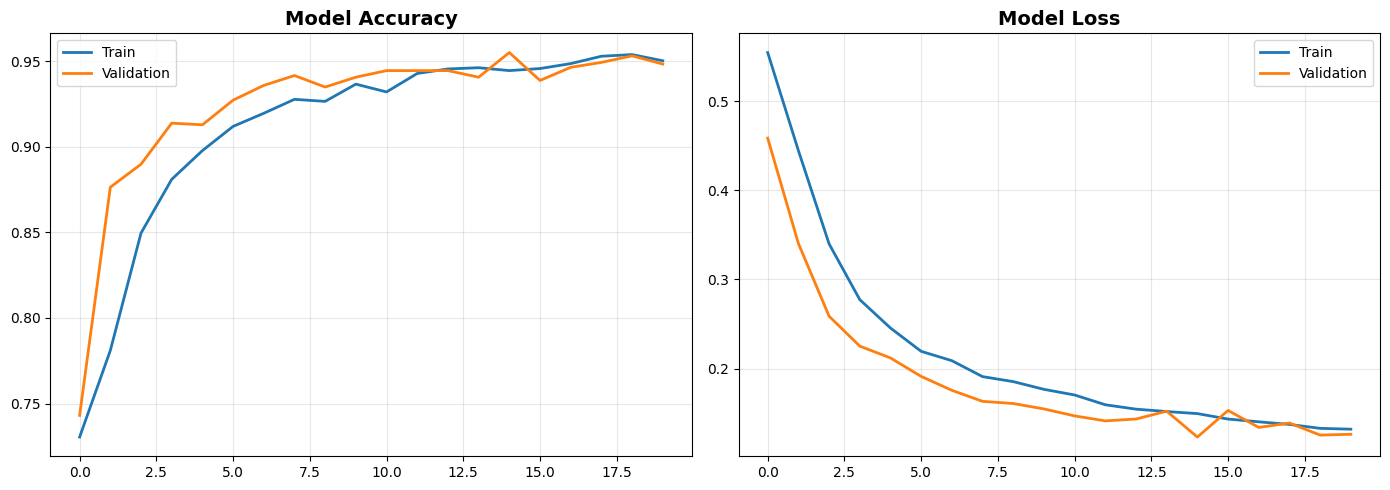

20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 704ms/step - accuracy: 0.8397 - loss: 0.4208 - precision: 0.8033 - recall: 0.9846

 Test Results:
Accuracy:  0.8397 (84.0%)
Recall:    0.9846 (98.5%)
Precision: 0.8033 (80.3%)
F1 Score:  0.8848


In [7]:
# Plot Accuracy & Loss
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation', linewidth=2)
plt.title('Model Accuracy', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation', linewidth=2)
plt.title('Model Loss', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Test Evaluation
test_loss, test_acc, test_recall, test_precision = model.evaluate(test_generator)
print(f"\n Test Results:")
print(f"Accuracy:  {test_acc:.4f} ({test_acc*100:.1f}%)")
print(f"Recall:    {test_recall:.4f} ({test_recall*100:.1f}%)")
print(f"Precision: {test_precision:.4f} ({test_precision*100:.1f}%)")
print(f"F1 Score:  {2 * (test_precision * test_recall) / (test_precision + test_recall):.4f}")

📤 Upload a chest X-Ray image:


Saving Screenshot 2026-07-03 235035.png to Screenshot 2026-07-03 235035.png


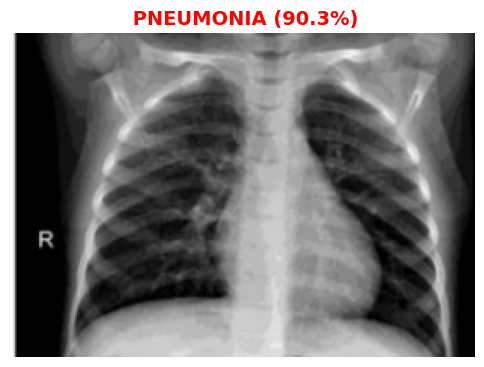

In [12]:
from google.colab import files
import cv2

print("📤 Upload a chest X-Ray image:")
uploaded = files.upload()

for filename in uploaded.keys():
    img = cv2.imread(filename)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (224, 224))
    img_array = np.expand_dims(img_resized, axis=0) / 255.0

    prediction = model.predict(img_array, verbose=0)[0][0]

    plt.figure(figsize=(6, 6))
    plt.imshow(img_rgb, cmap='gray')
    plt.axis('off')

    if prediction < 0.5:
        plt.title(f' NORMAL ({1-prediction:.1%})', fontsize=14, fontweight='bold', color='green')
    else:
        plt.title(f' PNEUMONIA ({prediction:.1%})', fontsize=14, fontweight='bold', color='red')

    plt.show()

In [13]:
model.save('pneumonia_detector.h5')
print("Model saved!")

Model saved!


In [14]:
import json
with open('class_info.json', 'w') as f:
    json.dump({'classes': ['NORMAL', 'PNEUMONIA']}, f)
files.download('class_info.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Naye format mein save (recommended for deployment)
model.save('pneumonia_detector.keras')
print("✅ Model saved in Keras format!")

# Download both
from google.colab import files
files.download('pneumonia_detector.keras')

✅ Model saved in Keras format!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>